In [5]:
from pathlib import Path
import sys

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "src").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

sys.path.insert(0, str(PROJECT_ROOT))

from src.data.tfrecord_loader import load_dataset, INPUT_FEATURES
import matplotlib.pyplot as plt

X, y = next(iter(load_dataset("train").take(1)))

X = X.numpy()
y = y.numpy()

print("Project:", PROJECT_ROOT)
print("X:", X.shape)
print("y:", y.shape)
print(INPUT_FEATURES)

Project: c:\Users\moham\OneDrive\Desktop\mvision\EmberWatch
X: (64, 64, 12)
y: (64, 64, 1)
('PrevFireMask', 'elevation', 'th', 'vs', 'tmmn', 'tmmx', 'sph', 'pr', 'pdsi', 'erc', 'NDVI', 'population')


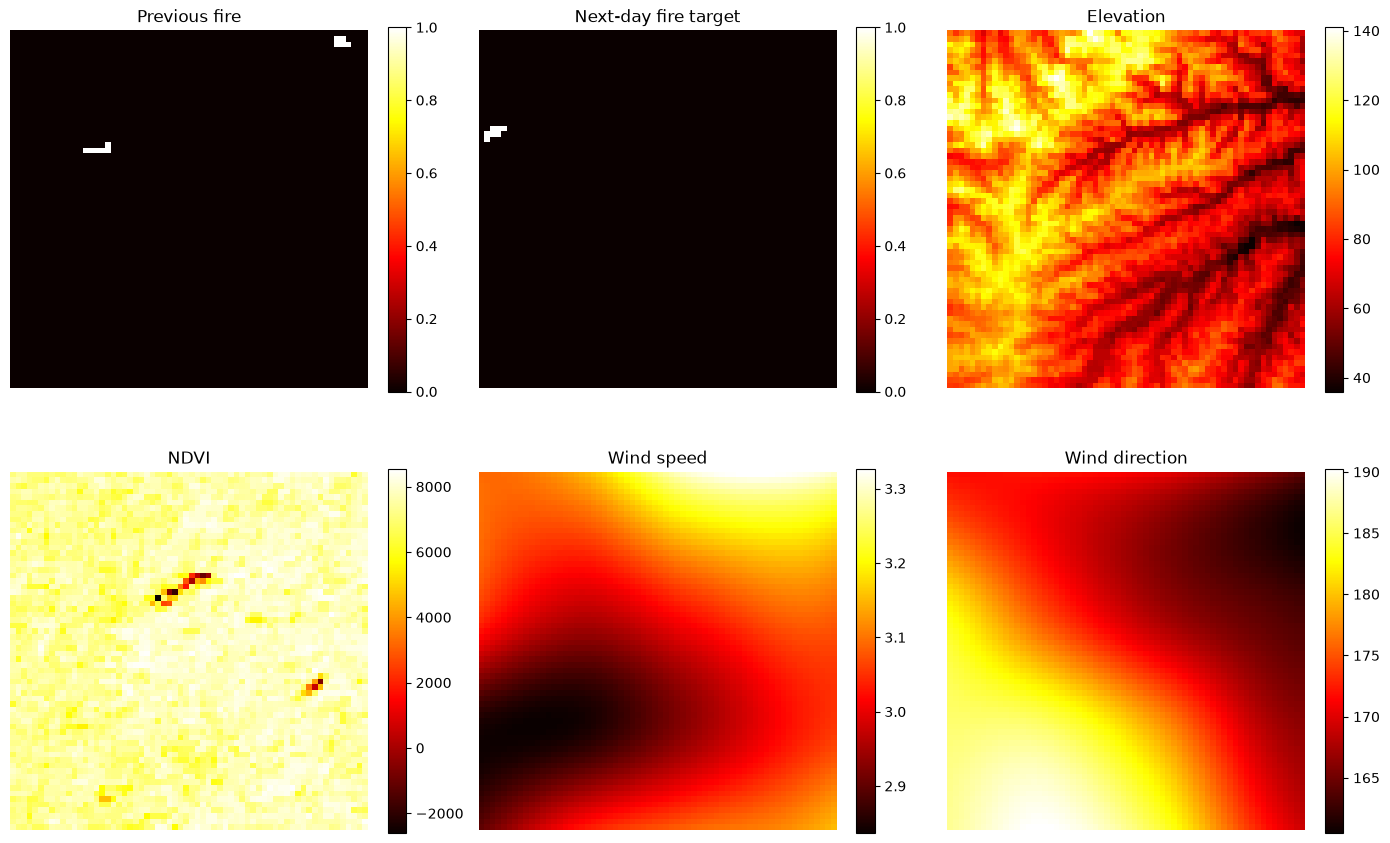

In [6]:
channels = {
    "Previous fire": "PrevFireMask",
    "Next-day fire target": "FireMask",
    "Elevation": "elevation",
    "NDVI": "NDVI",
    "Wind speed": "vs",
    "Wind direction": "th",
}

fig, axes = plt.subplots(2, 3, figsize=(14, 9))

for ax, (title, channel) in zip(axes.flat, channels.items()):
    image = y[..., 0] if channel == "FireMask" else X[..., INPUT_FEATURES.index(channel)]
    plot = ax.imshow(image, cmap="hot")
    ax.set_title(title)
    ax.axis("off")
    fig.colorbar(plot, ax=ax, fraction=0.046)

plt.tight_layout()
plt.show()

In [7]:
import numpy as np
from sklearn.metrics import (
    average_precision_score,
    f1_score,
    precision_score,
    recall_score,
)

def evaluate_persistence(split="eval", samples=200):
    targets = []
    previous_masks = []

    prev_index = INPUT_FEATURES.index("PrevFireMask")

    for X_batch, y_batch in load_dataset(split).take(samples):
        targets.append(y_batch.numpy().ravel())
        previous_masks.append(X_batch[..., prev_index].numpy().ravel())

    raw_y = np.concatenate(targets)
    raw_prev = np.concatenate(previous_masks)

    values, counts = np.unique(raw_y, return_counts=True)
    print("FireMask values:", dict(zip(values.astype(int), counts)))

    # Keep only known target pixels: 0=no fire, 1=fire.
    valid = np.isin(raw_y, [0, 1])
    y_true = (raw_y[valid] == 1).astype(int)

    # Persistence prediction: tomorrow's fire = today's known fire.
    y_score = (raw_prev[valid] == 1).astype(float)
    y_pred = (y_score >= 0.5).astype(int)

    print(f"Split: {split} | Samples: {samples}")
    print(f"Valid pixels: {valid.sum():,} / {len(valid):,}")
    print(f"AP:        {average_precision_score(y_true, y_score):.4f}")
    print(f"F1:        {f1_score(y_true, y_pred, zero_division=0):.4f}")
    print(f"Precision: {precision_score(y_true, y_pred, zero_division=0):.4f}")
    print(f"Recall:    {recall_score(y_true, y_pred, zero_division=0):.4f}")

evaluate_persistence()

FireMask values: {np.int64(-1): np.int64(38649), np.int64(0): np.int64(769315), np.int64(1): np.int64(11236)}
Split: eval | Samples: 200
Valid pixels: 780,551 / 819,200
AP:        0.0499
F1:        0.1945
Precision: 0.2126
Recall:    0.1792


In [8]:
import numpy as np

# ما نطبّعوش PrevFireMask لأنه mask: -1 / 0 / 1
CONTINUOUS_FEATURES = INPUT_FEATURES[1:]

def compute_channel_stats(samples=200):
    sums = np.zeros(len(CONTINUOUS_FEATURES), dtype=np.float64)
    sums_sq = np.zeros(len(CONTINUOUS_FEATURES), dtype=np.float64)
    counts = np.zeros(len(CONTINUOUS_FEATURES), dtype=np.int64)

    for X_batch, _ in load_dataset("train").take(samples):
        X_np = X_batch.numpy()

        for output_index, feature_name in enumerate(CONTINUOUS_FEATURES):
            channel_index = INPUT_FEATURES.index(feature_name)
            values = X_np[..., channel_index].ravel()
            values = values[np.isfinite(values)]

            sums[output_index] += values.sum()
            sums_sq[output_index] += np.square(values).sum()
            counts[output_index] += len(values)

    means = sums / counts
    stds = np.sqrt((sums_sq / counts) - np.square(means))

    for name, mean, std in zip(CONTINUOUS_FEATURES, means, stds):
        print(f"{name:12} mean={mean:12.4f}   std={std:12.4f}")

    return dict(zip(CONTINUOUS_FEATURES, zip(means, stds)))

CHANNEL_STATS = compute_channel_stats()

elevation    mean=    862.7343   std=    819.9610
th           mean=    111.3030   std=   3655.8843
vs           mean=      3.4180   std=      1.1909
tmmn         mean=    281.1420   std=     20.8172
tmmx         mean=    296.8010   std=     21.9027
sph          mean=      0.0063   std=      0.0036
pr           mean=      0.2982   std=      1.3627
pdsi         mean=     -0.8873   std=      2.3871
erc          mean=     53.4727   std=     25.9358
NDVI         mean=   5236.1072   std=   2217.2206
population   mean=     26.6171   std=    240.9713


In [9]:
def audit_channels(samples=200):
    for feature_name in CONTINUOUS_FEATURES:
        channel_index = INPUT_FEATURES.index(feature_name)
        values_all = []

        for X_batch, _ in load_dataset("train").take(samples):
            values = X_batch.numpy()[..., channel_index].ravel()
            values_all.append(values[np.isfinite(values)])

        values = np.concatenate(values_all)

        print(f"\n{feature_name}")
        print("min / max:", values.min(), "/", values.max())
        print("p01 / median / p99:",
              np.percentile(values, 1),
              np.median(values),
              np.percentile(values, 99))
        print("values < -1000:", (values < -1000).sum())
        print("values > 10000:", (values > 10000).sum())

audit_channels()


elevation
min / max: -5.0 / 4193.0
p01 / median / p99: 4.0 590.0 2919.0
values < -1000: 0
values > 10000: 0

th
min / max: -293490.75 / 21851.854
p01 / median / p99: 21.023327 191.6333 317.24075
values < -1000: 793
values > 10000: 207

vs
min / max: -20.47107 / 9.47794
p01 / median / p99: 1.3334217 3.2486556 6.837877
values < -1000: 0
values > 10000: 0

tmmn
min / max: 0.0 / 308.63483
p01 / median / p99: 258.63818 283.5453 296.41025
values < -1000: 0
values > 10000: 0

tmmx
min / max: 0.0 / 318.48624
p01 / median / p99: 272.22705 299.82556 313.1212
values < -1000: 0
values > 10000: 0

sph
min / max: -0.0049018273 / 0.07931579
p01 / median / p99: 0.00092642964 0.005382603 0.017216407
values < -1000: 0
values > 10000: 0

pr
min / max: -0.6727603 / 16.962973
p01 / median / p99: -0.022407884 0.0 7.931798
values < -1000: 0
values > 10000: 0

pdsi
min / max: -21.07106 / 15.738727
p01 / median / p99: -4.82633 -1.564739 5.1321287
values < -1000: 0
values > 10000: 0

erc
min / max: -847.87305 

In [10]:
def physical_validity_report(samples=200):
    rules = {
        "th": lambda v: (v < 0) | (v >= 360),
        "vs": lambda v: v < 0,
        "tmmn": lambda v: v <= 200,
        "tmmx": lambda v: v <= 200,
        "sph": lambda v: v < 0,
        "pr": lambda v: v < 0,
        "erc": lambda v: v < 0,
        "population": lambda v: v < 0,
    }

    for feature_name, invalid_rule in rules.items():
        channel_index = INPUT_FEATURES.index(feature_name)
        values_all = []

        for X_batch, _ in load_dataset("train").take(samples):
            values_all.append(X_batch.numpy()[..., channel_index].ravel())

        values = np.concatenate(values_all)
        invalid_count = invalid_rule(values).sum()

        print(
            f"{feature_name:12} "
            f"invalid: {invalid_count:,} / {len(values):,} "
            f"({invalid_count / len(values):.3%})"
        )

physical_validity_report()

th           invalid: 2,753 / 819,200 (0.336%)
vs           invalid: 6 / 819,200 (0.001%)
tmmn         invalid: 3,841 / 819,200 (0.469%)
tmmx         invalid: 3,841 / 819,200 (0.469%)
sph          invalid: 2 / 819,200 (0.000%)
pr           invalid: 80,998 / 819,200 (9.887%)
erc          invalid: 36 / 819,200 (0.004%)
population   invalid: 0 / 819,200 (0.000%)


In [11]:
VALID_RULES = {
    "elevation": lambda v: np.isfinite(v),
    "th": lambda v: (v >= 0) & (v < 360),
    "vs": lambda v: v >= 0,
    "tmmn": lambda v: v > 200,
    "tmmx": lambda v: v > 200,
    "sph": lambda v: v >= 0,
    "pr": lambda v: v >= 0,
    "pdsi": lambda v: np.isfinite(v),
    "erc": lambda v: v >= 0,
    "NDVI": lambda v: np.isfinite(v),
    "population": lambda v: v >= 0,
}

def compute_clean_stats(samples=200):
    stats = {}

    for feature_name in CONTINUOUS_FEATURES:
        channel_index = INPUT_FEATURES.index(feature_name)
        values_all = []

        for X_batch, _ in load_dataset("train").take(samples):
            values_all.append(X_batch.numpy()[..., channel_index].ravel())

        values = np.concatenate(values_all)
        valid_values = values[VALID_RULES[feature_name](values)]

        # Population and precipitation are very skewed.
        if feature_name in {"population", "pr"}:
            valid_values = np.log1p(valid_values)

        # Wind direction will become two layers, not one raw angle.
        if feature_name == "th":
            radians = np.deg2rad(valid_values)
            for derived_name, derived_values in {
                "th_sin": np.sin(radians),
                "th_cos": np.cos(radians),
            }.items():
                stats[derived_name] = {
                    "mean": float(derived_values.mean()),
                    "std": float(derived_values.std()),
                }
                print(
                    f"{derived_name:12} "
                    f"mean={stats[derived_name]['mean']:.4f}  "
                    f"std={stats[derived_name]['std']:.4f}"
                )
        else:
            stats[feature_name] = {
                "median": float(np.median(valid_values)),
                "mean": float(valid_values.mean()),
                "std": float(valid_values.std()),
            }
            print(
                f"{feature_name:12} "
                f"median={stats[feature_name]['median']:.4f}  "
                f"mean={stats[feature_name]['mean']:.4f}  "
                f"std={stats[feature_name]['std']:.4f}"
            )

    return stats

CLEAN_STATS = compute_clean_stats()

elevation    median=590.0000  mean=862.7342  std=819.9611
th_sin       mean=-0.1063  std=0.7464
th_cos       mean=-0.4118  std=0.5119
vs           median=3.2487  mean=3.4181  std=1.1903
tmmn         median=283.5952  mean=282.4662  std=7.8350
tmmx         median=299.8682  mean=298.1991  std=8.0682
sph          median=0.0054  mean=0.0063  std=0.0036
pr           median=0.0000  mean=0.1257  std=0.4189
pdsi         median=-1.5647  mean=-0.8873  std=2.3871
erc          median=50.6618  mean=53.4764  std=25.9141
NDVI         median=5384.0000  mean=5236.1074  std=2217.2207
population   median=0.1646  mean=0.9293  std=1.4090


In [12]:
from src.data.preprocessing import (
    CHANNELS,
    preprocess_inputs,
    preprocess_target,
)

X_clean = preprocess_inputs(X)
y_clean, valid_mask = preprocess_target(y)

print("Channels:", CHANNELS)
print("Clean X:", X_clean.shape)
print("Clean y:", y_clean.shape)
print("Valid target pixels:", int(valid_mask.numpy().sum()))

Channels: ('PrevFireMask', 'elevation', 'th_sin', 'th_cos', 'vs', 'tmmn', 'tmmx', 'sph', 'pr', 'pdsi', 'erc', 'NDVI', 'population')
Clean X: (64, 64, 13)
Clean y: (64, 64, 1)
Valid target pixels: 4096


In [13]:
from src.models.unet import build_unet, compile_unet

model = build_unet(input_shape=(64, 64, 13), base_filters=32)
model = compile_unet(model)

model.summary()

Model: "wildfire_unet"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ wildfire_inputs     │ (None, 64, 64,    │          0 │ -                 │
│ (InputLayer)        │ 13)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder1_conv1      │ (None, 64, 64,    │      3,776 │ wildfire_inputs[… │
│ (Conv2D)            │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder1_bn1        │ (None, 64, 64,    │        128 │ encoder1_conv1[0… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder1_relu1      │ (None, 64, 64,    │          0 │ encoder1_bn1[0][… │
│ (ReLU)              │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder1_conv2      │ (None, 64, 64,    │      9,248 │ encoder1_relu1[0… │
│ (Conv2D)            │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder1_bn2        │ (None, 64, 64,    │        128 │ encoder1_conv2[0… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder1_relu2      │ (None, 64, 64,    │          0 │ encoder1_bn2[0][… │
│ (ReLU)              │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1               │ (None, 32, 32,    │          0 │ encoder1_relu2[0… │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder2_conv1      │ (None, 32, 32,    │     18,496 │ pool1[0][0]       │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder2_bn1        │ (None, 32, 32,    │        256 │ encoder2_conv1[0… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder2_relu1      │ (None, 32, 32,    │          0 │ encoder2_bn1[0][… │
│ (ReLU)              │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder2_conv2      │ (None, 32, 32,    │     36,928 │ encoder2_relu1[0… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder2_bn2        │ (None, 32, 32,    │        256 │ encoder2_conv2[0… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder2_relu2      │ (None, 32, 32,    │          0 │ encoder2_bn2[0][… │
│ (ReLU)              │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool2               │ (None, 16, 16,    │          0 │ encoder2_relu2[0… │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder3_conv1      │ (None, 16, 16,    │     73,856 │ pool2[0][0]       │
│ (Conv2D)            │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder3_bn1        │ (None, 16, 16,    │        512 │ encoder3_conv1[0

 Total params: 1,934,113 (7.38 MB)

 Trainable params: 1,931,297 (7.37 MB)

 Non-trainable params: 2,816 (11.00 KB)

In [16]:
from importlib import reload

import src.data.tfrecord_loader as loader
import src.models.unet as unet_module

reload(loader)
reload(unet_module)

load_preprocessed_dataset = loader.load_preprocessed_dataset
train_ds = load_preprocessed_dataset(
    "train",
    batch_size=4,
    shuffle=True,
).take(20)

eval_ds = load_preprocessed_dataset(
    "eval",
    batch_size=4,
    shuffle=False,
).take(5)

model = unet_module.compile_unet(
    unet_module.build_unet(input_shape=(64, 64, 13), base_filters=32),
    learning_rate=1e-3,
    positive_weight=70.0,
)

history = model.fit(
    train_ds,
    validation_data=eval_ds,
    epochs=2,
)

Epoch 1/2


c:\Users\moham\OneDrive\Desktop\mvision\EmberWatch\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


20/20 ━━━━━━━━━━━━━━━━━━━━ 10s 145ms/step - loss: 0.9840 - pixel_accuracy: 0.7073 - precision: 0.0115 - recall: 0.4650 - val_loss: 2.8568 - val_pixel_accuracy: 0.1477 - val_precision: 0.0052 - val_recall: 0.9427
Epoch 2/2
20/20 ━━━━━━━━━━━━━━━━━━━━ 3s 113ms/step - loss: 0.8668 - pixel_accuracy: 0.8163 - precision: 0.0160 - recall: 0.4306 - val_loss: 3.2700 - val_pixel_accuracy: 0.1953 - val_precision: 0.0054 - val_recall: 0.9271


In [20]:
from sklearn.metrics import average_precision_score, precision_recall_curve
import numpy as np

def report_metrics(name, y_true, scores):
    ap = average_precision_score(y_true, scores)

    precision, recall, thresholds = precision_recall_curve(y_true, scores)
    f1_scores = 2 * precision * recall / (precision + recall + 1e-8)

    best_index = np.argmax(f1_scores[:-1])

    print(f"\n{name}")
    print(f"AP: {ap:.4f}")
    print(f"Best F1: {f1_scores[best_index]:.4f}")
    print(f"Best threshold: {thresholds[best_index]:.3f}")
    print(f"Precision: {precision[best_index]:.4f}")
    print(f"Recall: {recall[best_index]:.4f}")

def compare_unet_to_baseline(model, batches=25):
    y_true_all = []
    unet_scores_all = []
    persistence_scores_all = []

    dataset = load_preprocessed_dataset(
        "eval",
        batch_size=8,
        shuffle=False,
    ).take(batches)

    for X_batch, y_batch, valid_mask in dataset:
        x_np = X_batch.numpy()
        y_np = y_batch.numpy()
        mask_np = valid_mask.numpy().astype(bool)
        unet_np = model(X_batch, training=False).numpy()

        # الثلاثة عندهم نفس shape: (batch, 64, 64, 1)
        baseline_np = x_np[..., :1]

        y_true_all.append(y_np[mask_np])
        unet_scores_all.append(unet_np[mask_np])
        persistence_scores_all.append(baseline_np[mask_np])

    y_true = np.concatenate(y_true_all).astype(int)
    unet_scores = np.concatenate(unet_scores_all)
    persistence_scores = np.concatenate(persistence_scores_all)

    print(f"Valid evaluation pixels: {len(y_true):,}")
    print(f"Fire-pixel rate: {y_true.mean():.3%}")

    report_metrics("Persistence baseline", y_true, persistence_scores)
    report_metrics("Mini U-Net", y_true, unet_scores)

compare_unet_to_baseline(model)

Valid evaluation pixels: 780,551
Fire-pixel rate: 1.439%

Persistence baseline
AP: 0.0499
Best F1: 0.1945
Best threshold: 1.000
Precision: 0.2126
Recall: 0.1792

Mini U-Net
AP: 0.0279
Best F1: 0.0720
Best threshold: 1.000
Precision: 0.0447
Recall: 0.1843


In [21]:
from importlib import reload

reload(loader)
reload(unet_module)

train_ds = loader.load_preprocessed_dataset(
    "train",
    batch_size=4,
    shuffle=True,
).take(250)  # 250 × 4 = 1,000 samples

eval_ds = loader.load_preprocessed_dataset(
    "eval",
    batch_size=4,
    shuffle=False,
).take(50)   # 50 × 4 = 200 samples

model = unet_module.compile_unet(
    unet_module.build_unet(input_shape=(64, 64, 13), base_filters=32),
    learning_rate=1e-3,
    positive_weight=20.0,
)

history = model.fit(
    train_ds,
    validation_data=eval_ds,
    epochs=5,
    shuffle=False,
)

Epoch 1/5
250/250 ━━━━━━━━━━━━━━━━━━━━ 35s 117ms/step - loss: 0.4680 - pixel_accuracy: 0.9182 - precision: 0.0591 - recall: 0.4532 - val_loss: 3.4224 - val_pixel_accuracy: 0.4116 - val_precision: 0.0187 - val_recall: 0.8141
Epoch 2/5
250/250 ━━━━━━━━━━━━━━━━━━━━ 28s 111ms/step - loss: 0.3192 - pixel_accuracy: 0.9597 - precision: 0.1502 - recall: 0.6239 - val_loss: 0.4530 - val_pixel_accuracy: 0.9311 - val_precision: 0.1140 - val_recall: 0.5938
Epoch 3/5
250/250 ━━━━━━━━━━━━━━━━━━━━ 26s 104ms/step - loss: 0.2701 - pixel_accuracy: 0.9595 - precision: 0.1547 - recall: 0.6863 - val_loss: 0.4396 - val_pixel_accuracy: 0.9558 - val_precision: 0.1615 - val_recall: 0.5303
Epoch 4/5
250/250 ━━━━━━━━━━━━━━━━━━━━ 29s 113ms/step - loss: 0.2719 - pixel_accuracy: 0.9568 - precision: 0.1615 - recall: 0.7168 - val_loss: 0.4444 - val_pixel_accuracy: 0.8966 - val_precision: 0.0823 - val_recall: 0.6442
Epoch 5/5
250/250 ━━━━━━━━━━━━━━━━━━━━ 28s 110ms/step - loss: 0.2648 - pixel_accuracy: 0.9549 - precisio

In [22]:
compare_unet_to_baseline(model)

Valid evaluation pixels: 780,551
Fire-pixel rate: 1.439%

Persistence baseline
AP: 0.0499
Best F1: 0.1945
Best threshold: 1.000
Precision: 0.2126
Recall: 0.1792

Mini U-Net
AP: 0.1794
Best F1: 0.2631
Best threshold: 0.790
Precision: 0.2042
Recall: 0.3699


In [23]:
from pathlib import Path

ARTIFACTS_DIR = PROJECT_ROOT / "artifacts"
ARTIFACTS_DIR.mkdir(exist_ok=True)

MODEL_PATH = ARTIFACTS_DIR / "unet_m6_v1.keras"
model.save(MODEL_PATH)

print("Saved:", MODEL_PATH)

Saved: c:\Users\moham\OneDrive\Desktop\mvision\EmberWatch\artifacts\unet_m6_v1.keras


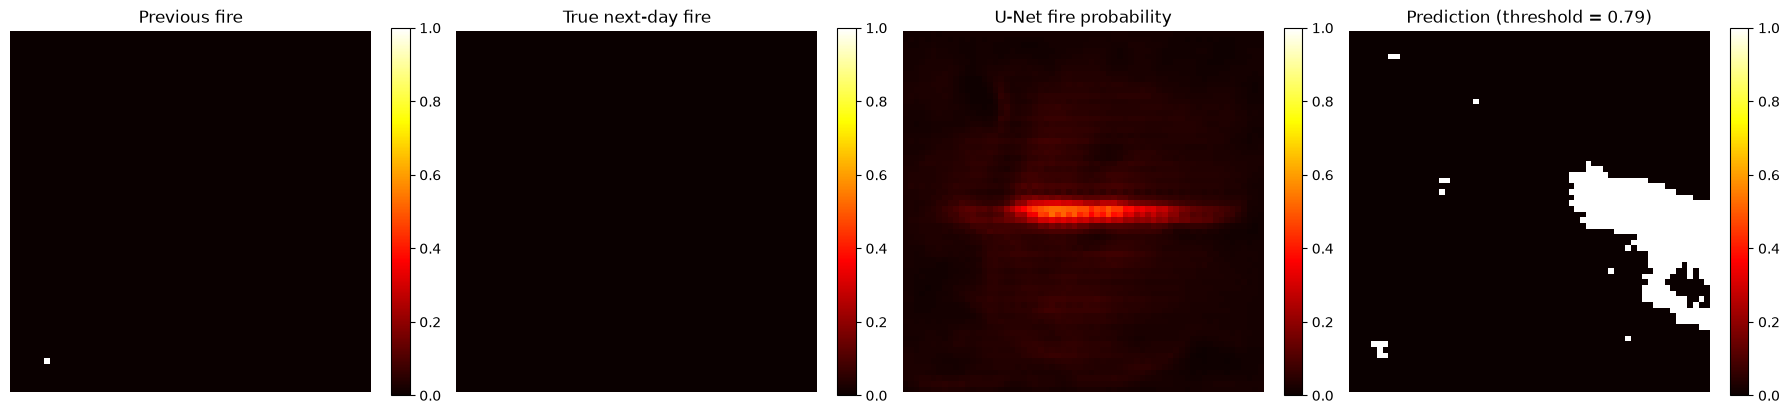

In [24]:
BEST_THRESHOLD = 0.79

# ناخذ example واحد من eval.
X_vis, y_vis, valid_vis = next(
    iter(loader.load_preprocessed_dataset("eval", batch_size=1))
)

probability = model(X_vis, training=False).numpy()[0, ..., 0]
previous_fire = X_vis.numpy()[0, ..., 0]
true_fire = y_vis.numpy()[0, ..., 0]
valid_pixels = valid_vis.numpy()[0, ..., 0].astype(bool)

prediction = np.where(
    valid_pixels,
    (probability >= BEST_THRESHOLD).astype(float),
    np.nan,
)

fig, axes = plt.subplots(1, 4, figsize=(18, 5))

plots = [
    (previous_fire, "Previous fire"),
    (true_fire, "True next-day fire"),
    (probability, "U-Net fire probability"),
    (prediction, f"Prediction (threshold = {BEST_THRESHOLD})"),
]

for ax, (image, title) in zip(axes, plots):
    result = ax.imshow(image, cmap="hot", vmin=0, vmax=1)
    ax.set_title(title)
    ax.axis("off")
    fig.colorbar(result, ax=ax, fraction=0.046)

plt.tight_layout()
plt.show()

In [26]:
import tensorflow as tf

In [27]:
def get_positive_example():
    dataset = loader.load_preprocessed_dataset(
        "eval",
        batch_size=1,
        shuffle=False,
    )

    for X_item, y_item, valid_item in dataset:
        fire_pixels = (y_item.numpy() * valid_item.numpy()).sum()

        if fire_pixels > 0:
            return X_item, y_item, valid_item

    raise ValueError("No positive fire example found.")

X_vis, y_vis, valid_vis = get_positive_example()

print("True fire pixels:", int((y_vis.numpy() * valid_vis.numpy()).sum()))

True fire pixels: 141


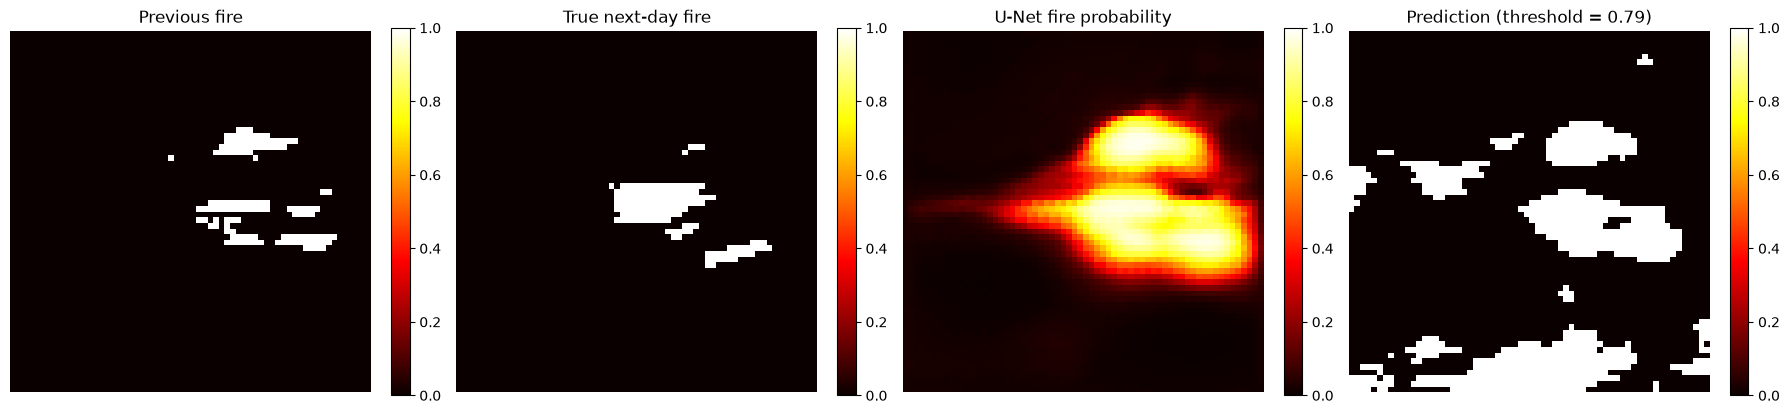

In [28]:
BEST_THRESHOLD = 0.79

probability = model(X_vis, training=False).numpy()[0, ..., 0]
previous_fire = X_vis.numpy()[0, ..., 0]
true_fire = y_vis.numpy()[0, ..., 0]
valid_pixels = valid_vis.numpy()[0, ..., 0].astype(bool)

prediction = np.where(
    valid_pixels,
    (probability >= BEST_THRESHOLD).astype(float),
    np.nan,
)

fig, axes = plt.subplots(1, 4, figsize=(18, 5))

plots = [
    (previous_fire, "Previous fire"),
    (true_fire, "True next-day fire"),
    (probability, "U-Net fire probability"),
    (prediction, f"Prediction (threshold = {BEST_THRESHOLD})"),
]

for ax, (image, title) in zip(axes, plots):
    result = ax.imshow(image, cmap="hot", vmin=0, vmax=1)
    ax.set_title(title)
    ax.axis("off")
    fig.colorbar(result, ax=ax, fraction=0.046)

plt.tight_layout()
plt.show()

In [29]:
train_ds = loader.load_preprocessed_dataset(
    "train",
    batch_size=4,
    shuffle=True,
).take(500)  # 2,000 train samples

eval_ds = loader.load_preprocessed_dataset(
    "eval",
    batch_size=4,
    shuffle=False,
).take(100)  # 400 eval samples

model_v2 = unet_module.compile_unet(
    unet_module.build_unet(input_shape=(64, 64, 13), base_filters=32),
    learning_rate=1e-3,
    positive_weight=10.0,
)

callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=2,
        restore_best_weights=True,
    )
]

history_v2 = model_v2.fit(
    train_ds,
    validation_data=eval_ds,
    epochs=5,
    shuffle=False,
    callbacks=callbacks,
)

Epoch 1/5
500/500 ━━━━━━━━━━━━━━━━━━━━ 61s 109ms/step - loss: 0.2646 - pixel_accuracy: 0.9703 - precision: 0.1588 - recall: 0.4027 - val_loss: 0.2790 - val_pixel_accuracy: 0.9593 - val_precision: 0.1416 - val_recall: 0.3918
Epoch 2/5
500/500 ━━━━━━━━━━━━━━━━━━━━ 52s 104ms/step - loss: 0.1850 - pixel_accuracy: 0.9713 - precision: 0.2130 - recall: 0.5988 - val_loss: 0.2710 - val_pixel_accuracy: 0.9608 - val_precision: 0.1581 - val_recall: 0.4331
Epoch 3/5
500/500 ━━━━━━━━━━━━━━━━━━━━ 53s 105ms/step - loss: 0.1676 - pixel_accuracy: 0.9719 - precision: 0.2241 - recall: 0.6523 - val_loss: 0.2680 - val_pixel_accuracy: 0.9612 - val_precision: 0.1689 - val_recall: 0.4702
Epoch 4/5
500/500 ━━━━━━━━━━━━━━━━━━━━ 53s 105ms/step - loss: 0.1640 - pixel_accuracy: 0.9709 - precision: 0.2311 - recall: 0.6821 - val_loss: 0.2633 - val_pixel_accuracy: 0.9470 - val_precision: 0.1413 - val_recall: 0.5691
Epoch 5/5
500/500 ━━━━━━━━━━━━━━━━━━━━ 54s 107ms/step - loss: 0.1595 - pixel_accuracy: 0.9713 - precisio

In [30]:
compare_unet_to_baseline(model_v2)

Valid evaluation pixels: 780,551
Fire-pixel rate: 1.439%

Persistence baseline
AP: 0.0499
Best F1: 0.1945
Best threshold: 1.000
Precision: 0.2126
Recall: 0.1792

Mini U-Net
AP: 0.1879
Best F1: 0.2924
Best threshold: 0.570
Precision: 0.2273
Recall: 0.4097


In [31]:
BEST_THRESHOLD = 0.57

MODEL_PATH = ARTIFACTS_DIR / "unet_m6_v2.keras"
model_v2.save(MODEL_PATH)

print("Saved:", MODEL_PATH)


Saved: c:\Users\moham\OneDrive\Desktop\mvision\EmberWatch\artifacts\unet_m6_v2.keras


In [32]:
from pathlib import Path

BEST_THRESHOLD = 0.57

ARTIFACTS_DIR = PROJECT_ROOT / "artifacts"
ARTIFACTS_DIR.mkdir(exist_ok=True)

MODEL_PATH = ARTIFACTS_DIR / "unet_m6_v2.keras"
model_v2.save(MODEL_PATH)

print("Saved:", MODEL_PATH)

Saved: c:\Users\moham\OneDrive\Desktop\mvision\EmberWatch\artifacts\unet_m6_v2.keras


In [33]:
from sklearn.metrics import (
    average_precision_score,
    f1_score,
    precision_score,
    recall_score,
)

def evaluate_on_test(model, threshold=BEST_THRESHOLD, batches=100):
    true_all = []
    probability_all = []
    baseline_all = []

    test_ds = loader.load_preprocessed_dataset(
        "test",
        batch_size=8,
        shuffle=False,
    ).take(batches)

    for X_batch, y_batch, valid_mask in test_ds:
        x_np = X_batch.numpy()
        y_np = y_batch.numpy()
        valid = valid_mask.numpy().astype(bool)

        probabilities = model(X_batch, training=False).numpy()
        persistence = x_np[..., :1]

        true_all.append(y_np[valid])
        probability_all.append(probabilities[valid])
        baseline_all.append(persistence[valid])

    y_true = np.concatenate(true_all).astype(int)
    scores = np.concatenate(probability_all)
    persistence = np.concatenate(baseline_all)

    prediction = (scores >= threshold).astype(int)
    baseline_prediction = (persistence >= 0.5).astype(int)

    print(f"Test valid pixels: {len(y_true):,}")
    print(f"Fire-pixel rate: {y_true.mean():.3%}")

    print("\nPersistence baseline")
    print(f"AP:        {average_precision_score(y_true, persistence):.4f}")
    print(f"F1:        {f1_score(y_true, baseline_prediction, zero_division=0):.4f}")

    print("\nU-Net v2 — fixed threshold 0.57")
    print(f"AP:        {average_precision_score(y_true, scores):.4f}")
    print(f"F1:        {f1_score(y_true, prediction, zero_division=0):.4f}")
    print(f"Precision: {precision_score(y_true, prediction, zero_division=0):.4f}")
    print(f"Recall:    {recall_score(y_true, prediction, zero_division=0):.4f}")

evaluate_on_test(model_v2)

Test valid pixels: 3,201,545
Fire-pixel rate: 1.480%

Persistence baseline
AP:        0.0864
F1:        0.2677

U-Net v2 — fixed threshold 0.57
AP:        0.2738
F1:        0.3649
Precision: 0.2890
Recall:    0.4947


In [ ]:
for index, (_, y_item, valid_item) in enumerate(
    loader.load_preprocessed_dataset("test", batch_size=1, shuffle=False)
):
    fire_pixels = int((y_item.numpy() * valid_item.numpy()).sum())

    if fire_pixels >= 100:
        print("Good demo index:", index)
        print("True fire pixels:", fire_pixels)
        break

Good demo index: 10
True fire pixels: 143


: 